In [42]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Données simples
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([2, 4, 6, 8, 10])

# Création et entraînement du modèle
modele = LinearRegression()
modele.fit(X, y)

# Paramètres appris
print("Coefficient :", modele.coef_)
print("Intercept :", modele.intercept_)

# Prédiction
print("Prédiction pour X=6 :", modele.predict([[6]]))

Coefficient : [2.]
Intercept : 0.0
Prédiction pour X=6 : [12.]


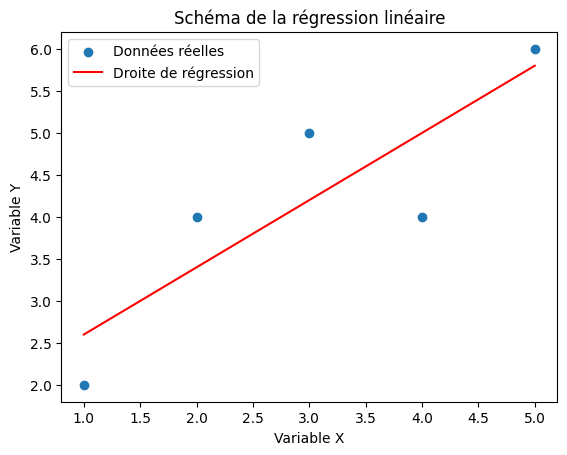

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([2, 4, 5, 4, 6])

modele = LinearRegression()
modele.fit(X, y)

predictions = modele.predict(X)

plt.scatter(X, y, label="Données réelles")
plt.plot(X, predictions, color="red", label="Droite de régression")

plt.xlabel("Variable X")
plt.ylabel("Variable Y")
plt.title("Schéma de la régression linéaire")
plt.legend()
plt.show()

In [44]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Budget publicitaire en milliers de DH
budget = np.array([[1], [2], [3], [4], [5]])

# Ventes en milliers de DH
ventes = np.array([10, 15, 20, 25, 30])

modele = LinearRegression()
modele.fit(budget, ventes)

# Prédire les ventes avec un budget de 6
prediction = modele.predict([[6]])

print("Ventes prédites :", prediction[0])

Ventes prédites : 35.0


In [45]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Chargement des données
jeu = load_diabetes()
X = jeu.data
y = jeu.target

# Séparation des données
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Tester deux configurations
for valeur in [True, False]:

    modele = LinearRegression(fit_intercept=valeur)
    modele.fit(X_train, y_train)

    predictions = modele.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    print("fit_intercept =", valeur)
    print("RMSE :", rmse)
    print("R² :", r2)
    print("-------------------")

fit_intercept = True
RMSE : 53.369566710321955
R² : 0.4849058889476756
-------------------
fit_intercept = False
RMSE : 165.27905182745235
R² : -3.9400899456107217
-------------------


PARTIE B

In [46]:
!pip -q install scikit-learn pandas numpy matplotlib seaborn


In [48]:

# PARTIE B — EXPÉRIMENTATION SUR DES DONNÉES PUBLIQUES

## Q5 — Choix et traçabilité des jeux de données

Pour cette partie, nous avons utilisé quatre jeux de données publics disponibles dans la bibliothèque Scikit-learn.

### 1. Diabetes
- Source : Scikit-learn.
- URL : https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset
- Taille : 442 observations et 10 caractéristiques.
- Cible : mesure quantitative de la progression du diabète.
- Type de problème : régression.

### 2. Breast Cancer Wisconsin
- Source : Scikit-learn.
- URL : https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset
- Taille : 569 observations et 30 caractéristiques.
- Cible : classification des tumeurs en deux classes.
- Type de problème : classification binaire.

### 3. Wine
- Source : Scikit-learn.
- URL : https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-dataset
- Taille : 178 observations et 13 caractéristiques.
- Cible originale : trois catégories de vins.
- Type de problème : clustering et réduction de dimension.

### 4. Digits
- Source : Scikit-learn.
- URL : https://scikit-learn.org/stable/datasets/toy_dataset.html#optical-recognition-of-handwritten-digits-dataset
- Taille : 1797 observations et 64 caractéristiques.
- Cible : chiffres manuscrits de 0 à 9.
- Type de problème : classification et réduction de dimension.

Les jeux de données sont chargés depuis Scikit-learn. Les conditions d'utilisation et les licences doivent être vérifiées dans la documentation de chaque dataset.

Date de consultation : 10/11/2026.


SyntaxError: unterminated string literal (detected at line 35) (1739230716.py, line 35)

In [49]:

# Q6 — Chargement et préparation des données réelles

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import (
    load_diabetes,
    load_breast_cancer,
    load_wine,
    load_digits
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

GRAINE = 42

# Chargement des datasets
diabetes = load_diabetes(as_frame=True)
cancer = load_breast_cancer(as_frame=True)
wine = load_wine(as_frame=True)
digits = load_digits()

# Conversion en DataFrames
df_diabetes = diabetes.frame.copy()
df_cancer = cancer.frame.copy()
df_wine = wine.frame.copy()

df_digits = pd.DataFrame(
    digits.data,
    columns=[f"pixel_{i}" for i in range(digits.data.shape[1])]
)

df_digits["target"] = digits.target

# Affichage des dimensions
print("DIABETES :", df_diabetes.shape)
print("BREAST CANCER :", df_cancer.shape)
print("WINE :", df_wine.shape)
print("DIGITS :", df_digits.shape)

# Affichage des premières observations
display(df_diabetes.head())
display(df_cancer.head())
display(df_wine.head())
display(df_digits.head())


DIABETES : (442, 11)
BREAST CANCER : (569, 31)
WINE : (178, 14)
DIGITS : (1797, 65)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


In [51]:

# Vérification des valeurs manquantes

datasets = {
    "Diabetes": df_diabetes,
    "Breast Cancer": df_cancer,
    "Wine": df_wine,
    "Digits": df_digits
}

for nom, df in datasets.items():

    print("\nDataset :", nom)

    print("Dimensions :", df.shape)

    print("Valeurs manquantes :")
    print(df.isnull().sum().sum())

    print("Nombre de doublons :")
    print(df.duplicated().sum())

    print("Types des variables :")
    print(df.dtypes.value_counts())



Dataset : Diabetes
Dimensions : (442, 11)
Valeurs manquantes :
0
Nombre de doublons :
0
Types des variables :
float64    11
Name: count, dtype: int64

Dataset : Breast Cancer
Dimensions : (569, 31)
Valeurs manquantes :
0
Nombre de doublons :
0
Types des variables :
float64    30
int64       1
Name: count, dtype: int64

Dataset : Wine
Dimensions : (178, 14)
Valeurs manquantes :
0
Nombre de doublons :
0
Types des variables :
float64    13
int64       1
Name: count, dtype: int64

Dataset : Digits
Dimensions : (1797, 65)
Valeurs manquantes :
0
Nombre de doublons :
0
Types des variables :
float64    64
int64       1
Name: count, dtype: int64


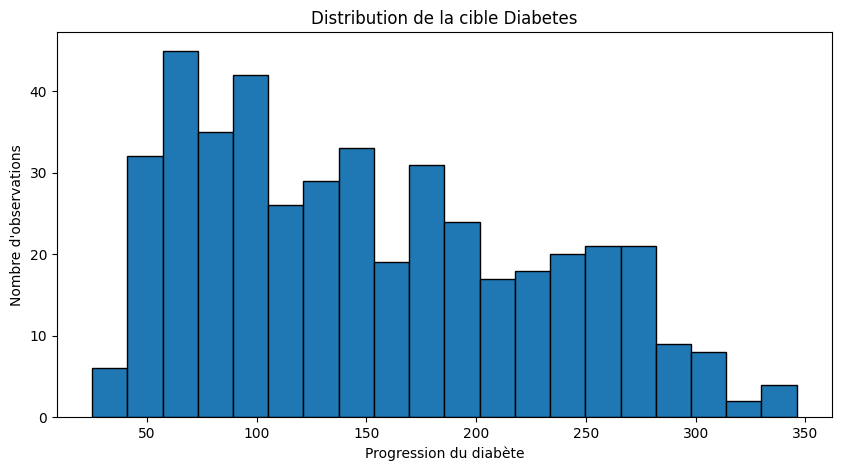

In [52]:

# Q6 — Visualisation des données

plt.figure(figsize=(10, 5))

plt.hist(
    diabetes.target,
    bins=20,
    edgecolor="black"
)

plt.title("Distribution de la cible Diabetes")
plt.xlabel("Progression du diabète")
plt.ylabel("Nombre d'observations")

plt.show()


Breast Cancer :
target
1    357
0    212
Name: count, dtype: int64

Wine :
target
1    71
0    59
2    48
Name: count, dtype: int64

Digits :
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


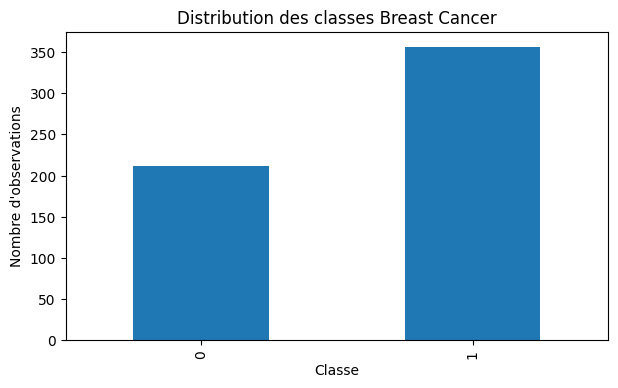

In [53]:

# Distribution des classes

print("Breast Cancer :")
print(cancer.target.value_counts())

print("\nWine :")
print(wine.target.value_counts())

print("\nDigits :")
print(pd.Series(digits.target).value_counts().sort_index())

# Visualisation du dataset Breast Cancer

plt.figure(figsize=(7, 4))

pd.Series(cancer.target).value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution des classes Breast Cancer")
plt.xlabel("Classe")
plt.ylabel("Nombre d'observations")

plt.show()


In [54]:

# Séparation entraînement / test

X_reg = diabetes.data
y_reg = diabetes.target

X_cls = cancer.data
y_cls = cancer.target

X_digits = digits.data
y_digits = digits.target

# Régression
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.25,
    random_state=GRAINE
)

# Classification Breast Cancer
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.25,
    random_state=GRAINE,
    stratify=y_cls
)

# Classification Digits
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_digits,
    y_digits,
    test_size=0.25,
    random_state=GRAINE,
    stratify=y_digits
)

print("Diabetes train :", Xr_train.shape)
print("Diabetes test :", Xr_test.shape)

print("Cancer train :", Xc_train.shape)
print("Cancer test :", Xc_test.shape)

print("Digits train :", Xd_train.shape)
print("Digits test :", Xd_test.shape)


Diabetes train : (331, 10)
Diabetes test : (111, 10)
Cancer train : (426, 30)
Cancer test : (143, 30)
Digits train : (1347, 64)
Digits test : (450, 64)


In [55]:

# Q7 — Expérimentation : régression

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Modèles de régression
modeles_regression = {
    "Régression linéaire": LinearRegression(),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1, max_iter=10000))
    ]),

    "Arbre de régression": DecisionTreeRegressor(
        max_depth=4,
        random_state=GRAINE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=GRAINE
    )
}

resultats_regression = []

for nom, modele in modeles_regression.items():

    modele.fit(Xr_train, yr_train)

    predictions = modele.predict(Xr_test)

    mae = mean_absolute_error(
        yr_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            yr_test,
            predictions
        )
    )

    r2 = r2_score(
        yr_test,
        predictions
    )

    resultats_regression.append({
        "Algorithme": nom,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

df_resultats_regression = pd.DataFrame(
    resultats_regression
)

display(
    df_resultats_regression.sort_values(
        "RMSE"
    )
)


,Algorithme,MAE,RMSE,R2
2,Lasso,41.484718,53.281974,0.486595
1,Ridge,41.507342,53.318239,0.485896
0,Régression linéaire,41.548507,53.369567,0.484906
4,Random Forest,43.736396,54.864493,0.455645
3,Arbre de régression,46.770106,59.651587,0.356508


In [56]:

# Q7 — Expérimentation : classification Breast Cancer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

modeles_classification = {

    "Régression logistique": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=GRAINE
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Arbre de décision": DecisionTreeClassifier(
        max_depth=4,
        random_state=GRAINE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=GRAINE
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            random_state=GRAINE
        ))
    ])
}

resultats_classification = []

for nom, modele in modeles_classification.items():

    modele.fit(Xc_train, yc_train)

    predictions = modele.predict(Xc_test)

    probabilites = modele.predict_proba(
        Xc_test
    )[:, 1]

    resultats_classification.append({

        "Algorithme": nom,

        "Accuracy": accuracy_score(
            yc_test,
            predictions
        ),

        "Precision": precision_score(
            yc_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            yc_test,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            yc_test,
            predictions,
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            yc_test,
            probabilites
        )
    })

df_resultats_classification = pd.DataFrame(
    resultats_classification
)

display(
    df_resultats_classification.sort_values(
        "F1",
        ascending=False
    )
)


,Algorithme,Accuracy,Precision,Recall,F1,ROC_AUC
0,Régression logistique,0.986014,0.988889,0.988889,0.988889,0.997694
1,KNN,0.979021,0.967742,1.000000,0.983607,0.984486
4,SVM,0.979021,0.988764,0.977778,0.983240,0.996855
3,Random Forest,0.958042,0.956522,0.977778,0.967033,0.994969
2,Arbre de décision,0.944056,0.955556,0.955556,0.955556,0.938365


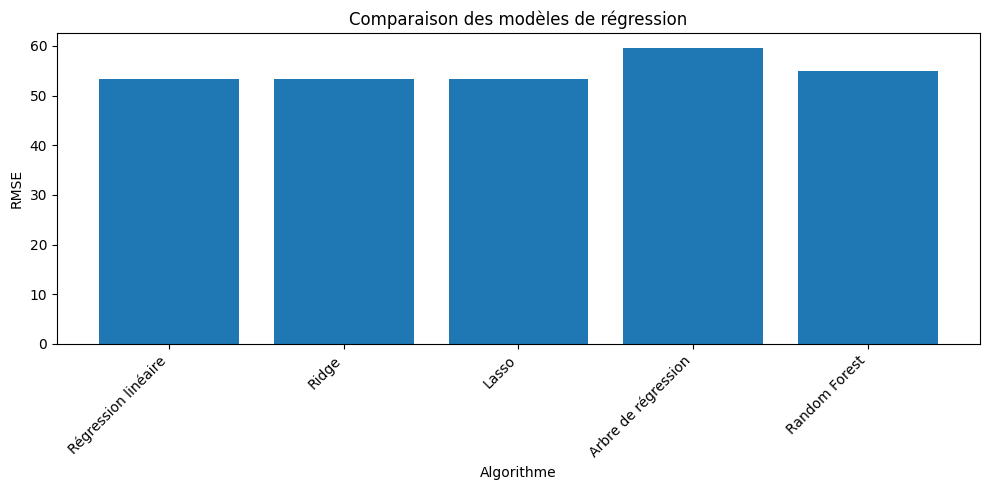

In [57]:

# Q8 — Comparaison des modèles de régression

plt.figure(figsize=(10, 5))

plt.bar(
    df_resultats_regression["Algorithme"],
    df_resultats_regression["RMSE"]
)

plt.title("Comparaison des modèles de régression")
plt.xlabel("Algorithme")
plt.ylabel("RMSE")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


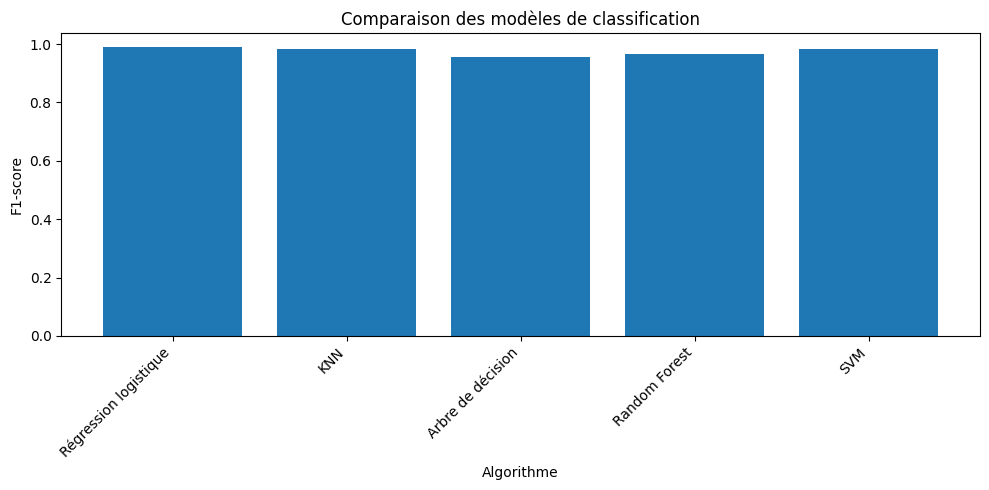

In [58]:

# Q8 — Comparaison des modèles de classification

plt.figure(figsize=(10, 5))

plt.bar(
    df_resultats_classification["Algorithme"],
    df_resultats_classification["F1"]
)

plt.title("Comparaison des modèles de classification")
plt.xlabel("Algorithme")
plt.ylabel("F1-score")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


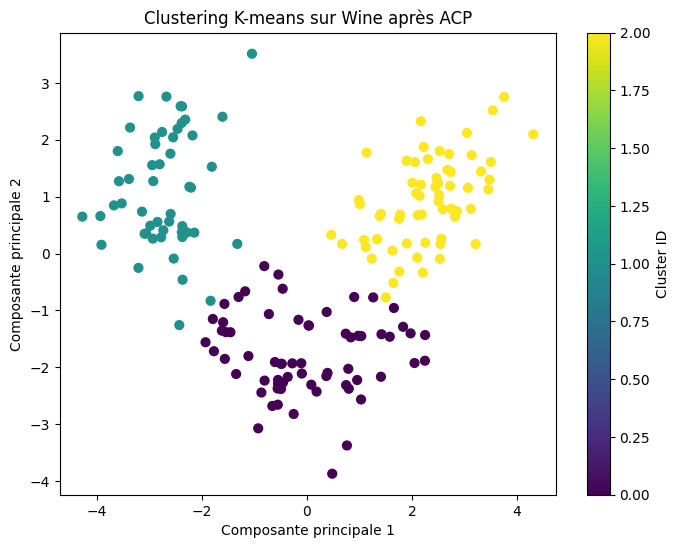

Variance expliquée par les deux composantes : 0.554


In [60]:

# Q8 — Visualisation des groupes Wine avec ACP

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Préparation et normalisation des données Wine (sans la cible)
X_wine = df_wine.drop(columns=["target"])
scaler = StandardScaler()
X_wine_scaled = scaler.fit_transform(X_wine)

# 2. Application de K-Means pour obtenir les labels
kmeans_wine = KMeans(n_clusters=3, random_state=GRAINE, n_init=10)
labels_kmeans = kmeans_wine.fit_predict(X_wine_scaled)

# 3. Application de l'ACP
pca_wine = PCA(
    n_components=2,
    random_state=GRAINE
)

X_wine_pca = pca_wine.fit_transform(
    X_wine_scaled
)

# 4. Visualisation
plt.figure(figsize=(8, 6))

plt.scatter(
    X_wine_pca[:, 0],
    X_wine_pca[:, 1],
    c=labels_kmeans,
    cmap="viridis",
    s=40
)

plt.title("Clustering K-means sur Wine après ACP")
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")

plt.colorbar(label="Cluster ID")
plt.show()

print(
    "Variance expliquée par les deux composantes :",
    round(
        pca_wine.explained_variance_ratio_.sum(),
        3
    )
)
